# Redes Neuronales 2026

---

# Guía de ejercicios N.º 11: Clasificación de imágenes del conjunto Fashion-MNIST con PyTorch

Esta guía continúa con el hilo conceptual utilizado en la guía de *Autoencoder*, pero ahora la tarea es **clasificación supervisada**.

En el *autoencoder* la idea era reproducir la imagen de entrada luego de realizar una representación en el **espacio latente**:

$$
x \longrightarrow \hat{x}.
$$

Ahora queremos aprender:

$$
x \longrightarrow y,
$$

donde $y$ es la **clase correcta** de la imagen.

En este caso, la red no reconstruirá las imágenes. En cambio, producirá **10 logits**, uno por cada clase, y utilizaremos las etiquetas de Fashion-MNIST como objetivos.

> **Observación:** *train* se utiliza para actualizar parámetros, *validation* para comparar configuraciones y *test* se reserva para la evaluación final.

## Ejercicio 1) Preparar el entorno

### 1.1) Importar librerías

Usaremos las mismas herramientas básicas que en la guía anterior: PyTorch, `torchvision`, `DataLoader` y Matplotlib.

In [ ]:
import random

import matplotlib.pyplot as plt
import numpy as np
import torch

from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms


# p/Visualizar la arquitectura de la red
%pip install graphviz
from graphviz import Digraph
from IPython.display import display

### 1.2) Reproducibilidad y dispositivo

Fijamos semillas y elegimos automáticamente GPU si está disponible.

In [ ]:
SEED = 42
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("PyTorch:", torch.__version__)
print("Dispositivo:", device)

PyTorch: 2.14.1+cu130
Dispositivo: cuda


## Ejercicio 2) Cargar y preparar Fashion-MNIST

### 2.1) Transformación

En clasificación no necesitamos que la salida de la red tenga el mismo rango que los píxeles de entrada. Por eso podemos reescalar las imágenes al intervalo `[-1,1]`.

Primero `ToTensor()` lleva los píxeles a `[0,1]`. Luego:

$$
x_{\mathrm{norm}}
=
\frac{x-0.5}{0.5}.
$$

Así obtenemos:

$$
x_{\mathrm{norm}}\in[-1,1].
$$

**Observación:** esta transformación **reescala** los píxeles, pero **no centra** los datos. Como la mayoría de los píxeles de Fashion-MNIST corresponden al fondo (negro, $x=0$, que se transforma en $x_{\mathrm{norm}}=-1$), la media de los píxeles normalizados es aproximadamente $-0.43$, y no cero. Lo importante aquí es que las entradas tomen valores de orden 1, de modo que las preactivaciones de la primera capa tengan una escala razonable.

Una alternativa es **estandarizar** las entradas utilizando la media y el desvío estándar de los píxeles de Fashion-MNIST ($\mu\approx0.286$, $\sigma\approx0.353$):

```python
transforms.Normalize((0.286,), (0.353,))
```

con lo cual las entradas quedan, en promedio, con media cero y varianza unitaria.

Esta elección es distinta de la del *autoencoder*: allí utilizábamos `[0,1]` porque la salida `Sigmoid` debía reconstruir los valores de los píxeles en `[0,1]`.

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

### 2.2) *Train*, *validation* y *test*

Usaremos la misma metodología que en la guía del *autoencoder*:

- 50.000 imágenes para *train*;
- 10.000 imágenes para *validation*;
- 10.000 imágenes oficiales para *test*.

No visualizaremos nuevamente el *dataset* (ya lo hicimos en la guía de práctico del *Autoencoder*). Nos concentraremos directamente en la **tarea de clasificación**.

In [ ]:
full_train_set = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

test_set = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

split_generator = torch.Generator().manual_seed(SEED)

train_set, validation_set = random_split(
    full_train_set,
    [50_000, 10_000],
    generator=split_generator
)


print("------------------")
print("Train:", len(train_set))
print("Validation:", len(validation_set))
print("Test:", len(test_set))

------------------
Train: 50000
Validation: 10000
Test: 10000


### 2.3) Nombres de las clases

Fashion-MNIST codifica las categorías con **números enteros** de `0` a `9`.

El siguiente **diccionario** sólo se utilizará para traducir las **etiquetas numéricas** a **nombres legibles** cuando analicemos las predicciones.

In [ ]:
class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot",
}

## Ejercicio 3) Crear los `DataLoader`s

Como en el *autoencoder*, el entrenamiento se realiza **mini-batch por mini-batch**.

Usaremos *mini-batches* de 100 imágenes:

```text
images.shape = (B, 1, 28, 28)
labels.shape = (B,)
```

`train_loader` usa `shuffle=True`. *Validation* y *test* usan `shuffle=False`.

In [ ]:
BATCH_SIZE = 100

train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True
)

validation_loader = DataLoader(
    validation_set,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_set,
    batch_size=BATCH_SIZE,
    shuffle=False
)

images, labels = next(iter(train_loader))

print("images.shape:", images.shape)
print("labels.shape:", labels.shape)

images.shape: torch.Size([100, 1, 28, 28])
labels.shape: torch.Size([100])


## Ejercicio 4) Comprender la tarea de clasificación

En un *autoencoder*:

$$
x\longrightarrow\hat{x}.
$$

En **clasificación supervisada**:

$$
x\longrightarrow y.
$$

Para una imagen, la red producirá un vector de 10 valores:

$$
\mathbb{z}
=
[z_0,z_1,\ldots,z_9]^T,
$$

donde cada $z_k$ es un *logit* para la clase $k$.

Los logits:

- son números reales;
- no son probabilidades;
- no tienen que estar entre 0 y 1;
- no tienen que sumar 1.

Conceptualmente, *softmax* transforma los *logits* en **probabilidades**:

$$
p_k
=
\frac{e^{z_k}}
{\sum_{j=0}^{9}e^{z_j}}.
$$

La clase predicha es la de mayor *logit*, equivalentemente la de **mayor probabilidad**:

$$
\hat{y}
=
\operatorname*{arg\,max}_k z_k.
$$

A diferencia del *autoencoder*, aquí **sí necesitamos las etiquetas** (por etiquetas nos referimos a los números enteros entre 0 y 9 que denotan cada clase, no nos referimos a los nombres de las clases) porque ellas indican cuál de las 10 clases es la correcta.

## Ejercicio 5) Definir la red de clasificación

Usaremos una MLP **completamente conectada**:

$$
784
\longrightarrow
128
\longrightarrow
64
\longrightarrow
10.
$$

Para un *mini-batch*:

$$
(B,1,28,28)
\longrightarrow
(B,784)
\longrightarrow
(B,128)
\longrightarrow
(B,64)
\longrightarrow
(B,10).
$$

La última capa produce 10 *logits*. No agregamos `Softmax` al modelo porque `CrossEntropyLoss` trabaja directamente con *logits*.

Incluiremos `Dropout(p=0.2)` después de las activaciones ocultas.

In [ ]:
class Clasificador(nn.Module):
    def __init__(self, p_dropout=0.2):
        super().__init__()

        self.red = nn.Sequential(
            nn.Flatten(),                # (B, 1, 28, 28) → (B, 784)
            nn.Linear(28 * 28, 128),     # (B, 784) → (B, 128)
            nn.ReLU(),
            nn.Dropout(p_dropout),
            nn.Linear(128, 64),          # (B, 128) → (B, 64)
            nn.ReLU(),
            nn.Dropout(p_dropout),
            nn.Linear(64, 10),           # (B, 64) → (B, 10)
        )

    def forward(self, x):
        return self.red(x)


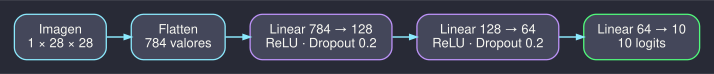

In [ ]:
# Construcción de la arqui del modelo
diagrama = Digraph("Clasificador")

diagrama.attr(
    rankdir="LR",
    bgcolor="#282A36",
    pad="0.2",
    ranksep="0.35"
)

diagrama.attr(
    "node",
    shape="box",
    style="rounded,filled",
    fillcolor="#44475A",
    color="#BD93F9",
    fontcolor="#F8F8F2",
    fontname="Helvetica",
    fontsize="13",
    penwidth="1.3",
    margin="0.16,0.12"
)

diagrama.attr(
    "edge",
    color="#8BE9FD",
    penwidth="1.5",
    arrowsize="0.7"
)

diagrama.node(
    "entrada",
    "Imagen\n1 × 28 × 28",
    color="#8BE9FD"
)

diagrama.node(
    "flatten",
    "Flatten\n784 valores",
    color="#8BE9FD"
)

diagrama.node(
    "oculta1",
    "Linear 784 → 128\nReLU · Dropout 0.2"
)

diagrama.node(
    "oculta2",
    "Linear 128 → 64\nReLU · Dropout 0.2"
)

diagrama.node(
    "salida",
    "Linear 64 → 10\n10 logits",
    color="#50FA7B"
)

diagrama.edges([
    ("entrada", "flatten"),
    ("flatten", "oculta1"),
    ("oculta1", "oculta2"),
    ("oculta2", "salida")
])

display(diagrama)

### 5.1) Comprobar dimensiones

Antes de entrenar, verificamos el *forward pass*.

Para $B$ imágenes y 10 clases esperamos:

$$
(B,1,28,28)
\longrightarrow
(B,10).
$$

In [ ]:
model_example = Clasificador()

with torch.no_grad():
    classes = model_example(images)

print("Entradas:", images.shape)
print("Clases obtenidas:", classes.shape)

Entradas: torch.Size([100, 1, 28, 28])
Clases obtenidas: torch.Size([100, 10])


## Ejercicio 6) Función de pérdida

Para **clasificación multiclase** utilizaremos la función de pérdida denominada **Entropía Cruzada** ($L$) (`CrossEntropyLoss`).

Para un ejemplo cuya clase verdadera es $y$, conceptualmente:

$$
L
=
-\log(p_y),
$$

donde $p_y$ es la probabilidad asignada por *softmax* a la **clase correcta**.

PyTorch implementa de manera numéricamente estable la combinación:

```text
logits → log-softmax → negative log-likelihood
```

Por eso:

- la red debe devolver **logits**;
- no aplicamos `Softmax` antes de la pérdida;
- las etiquetas son enteros entre `0` y `9`, no vectores *one-hot*.

In [ ]:
loss_fn = nn.CrossEntropyLoss()

## Ejercicio 7) Elegir el optimizador

Usaremos las mismas dos opciones que en la guía del *autoencoder*:

- SGD: `lr=0.01`;
- Adam: `lr=0.001`.

Comenzaremos con *Adam* y luego compararemos ambas configuraciones utilizando *validation*.

In [ ]:
SGD_LR = 0.01
ADAM_LR = 0.001
OPTIMIZER_NAME = "Adam"

## Ejercicio 8) Implementar una época de entrenamiento

El `DataLoader` entrega *mini-batches*:

```python
for images, labels in data_loader:
```

Para cada *mini-batch*:

1. activar modo **entrenamiento**;
2. mover imágenes y etiquetas al dispositivo;
3. borrar gradientes anteriores;
4. hacer *forward*;
5. calcular *Cross-Entropy Loss*;
6. hacer *backpropagation*;
7. actualizar parámetros.

Como en el *Autoencoder*, `optimizer.step()` es la instrucción que modifica los pesos.

In [ ]:
def train_one_epoch(model, data_loader, loss_fn, optimizer, device):
    model.train() # Activo modo entrenamiento

    for images, labels in data_loader:
        images = images.to(device) #Imágenes -> Dispositivo
        labels = labels.to(device) #Labels -> Dispositivo

        optimizer.zero_grad() #Borro los gradientes anteriores

        logits = model(images) #Forward

        loss = loss_fn(logits, labels) #Calculo la Cross-Entropy Loss

        loss.backward()#Backpropagation

        optimizer.step()#Actualizo los parámetros

## Ejercicio 9) Implementar la evaluación

Durante evaluación:

- usamos `model.eval()`;
- desactivamos el cálculo de gradientes;
- no actualizamos parámetros;
- calculamos tanto pérdida (*loss*) como *accuracy*.

Para cada *mini-batch*:

```python
predictions = logits.argmax(dim=1)
```

selecciona la clase de mayor *logit* para cada imagen.

In [ ]:
@torch.no_grad()
def evaluate(model, data_loader, loss_fn, device):
    model.eval() #Desactivamos dropout

    total_loss = 0.0
    total_examples = 0
    total_correct = 0

    for images, labels in data_loader:

        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)

        loss = loss_fn(logits, labels)

        batch_size = images.size(0)
        predictions = logits.argmax(dim=1)

        total_loss += loss.item() * batch_size
        total_correct += (predictions == labels).sum().item()
        total_examples += batch_size

    mean_loss = total_loss / total_examples
    accuracy = total_correct / total_examples

    return mean_loss, accuracy


## Ejercicio 10) Crear el modelo y el optimizador

Ahora creamos una instancia nueva del modelo y asociamos el optimizador seleccionado a sus parámetros.

In [ ]:
torch.manual_seed(SEED)

model = Clasificador().to(device)

if OPTIMIZER_NAME == "SGD":
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=SGD_LR
    )

elif OPTIMIZER_NAME == "Adam":
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=ADAM_LR
    )

else:
    raise ValueError("OPTIMIZER_NAME debe ser 'SGD' o 'Adam'.")

print("Optimizador:", OPTIMIZER_NAME)

Optimizador: Adam


### 10.1) Predicciones antes del entrenamiento

Antes del entrenamiento, los pesos son aleatorios. Por eso no esperamos predicciones útiles.

Usaremos *validation*, NO *test*, para observar algunas predicciones iniciales.

Esta sección cumple el mismo rol conceptual que las reconstrucciones antes de  entrenar el *autoencoder*: mostrar que la arquitectura por sí sola no sabe cómo clasificar imágenes correctamente todavía.

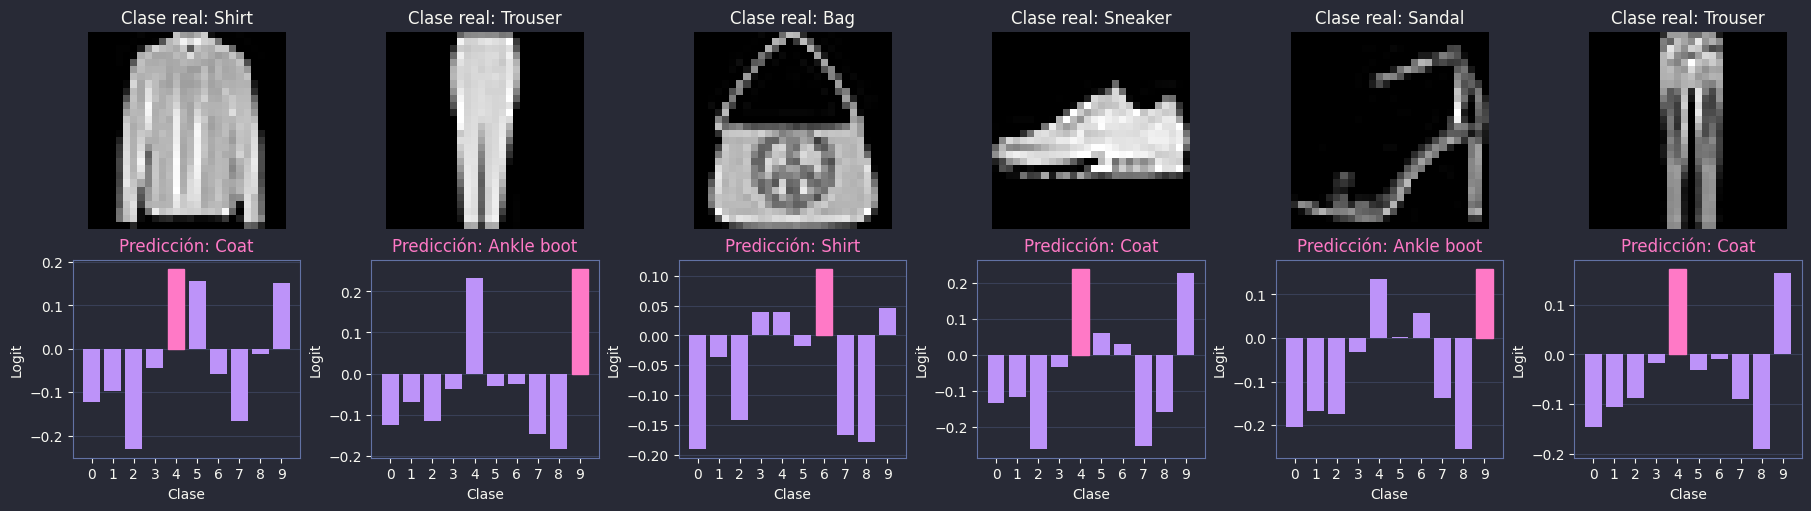

In [ ]:
@torch.no_grad()
def show_untrained_classifications(model, data_loader, device, n=6):
    model.eval()

    fondo = "#282A36"
    texto = "#F8F8F2"
    grilla = "#6272A4"
    violeta = "#BD93F9"
    rosa = "#FF79C6"

    images, labels = next(iter(data_loader))
    images = images[:n]
    labels = labels[:n]
    n = images.size(0)

    logits = model(images.to(device)).cpu()
    predictions = logits.argmax(dim=1)

    fig, axes = plt.subplots(
        2, n,
        figsize=(3 * n, 5),
        facecolor=fondo,
        layout="constrained",
        squeeze=False
    )

    for i in range(n):
        real = labels[i].item()
        pred = predictions[i].item()

        ax_image = axes[0, i]
        ax_image.set_facecolor(fondo)
        ax_image.imshow(images[i, 0].cpu(), cmap="gray")
        ax_image.set_title(
            f"Clase real: {class_names[real]}",
            color=texto
        )
        ax_image.axis("off")

        ax_bar = axes[1, i]
        ax_bar.set_facecolor(fondo)

        bars = ax_bar.bar(
            range(10), logits[i].numpy(),
            color=violeta, zorder=3
        )
        bars[pred].set_color(rosa)

        ax_bar.set_title(
            f"Predicción: {class_names[pred]}",
            color=rosa
        )
        ax_bar.set_xticks(range(10))
        ax_bar.set_xlabel("Clase", color=texto)
        ax_bar.set_ylabel("Logit", color=texto)
        ax_bar.tick_params(colors=texto)
        ax_bar.grid(axis="y", color=grilla, alpha=0.3)
        ax_bar.set_axisbelow(True)

        for borde in ax_bar.spines.values():
            borde.set_color(grilla)

    plt.show()


show_untrained_classifications(model, validation_loader, device)

## Ejercicio 11) Entrenar el modelo

En cada época:

```text
actualizar parámetros usando train
        ↓
evaluar train con los pesos finales
        ↓
evaluar validation con los mismos pesos
```

Así las métricas de *train* y *validation* corresponden exactamente al mismo estado del modelo.

Como en la guía del *autoencoder*, `train_one_epoch()` sólo actualiza pesos; las métricas se calculan después con `evaluate()`.

In [ ]:
EPOCHS = 10

history = {
    "train_loss": [],
    "train_accuracy": [],
    "validation_loss": [],
    "validation_accuracy": []
}

for epoch in range(1, EPOCHS + 1):
    train_one_epoch(
        model,
        train_loader,
        loss_fn,
        optimizer,
        device
    )

    train_loss, train_accuracy = evaluate(
        model,
        train_loader,
        loss_fn,
        device
    )

    validation_loss, validation_accuracy = evaluate(
        model,
        validation_loader,
        loss_fn,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["validation_loss"].append(validation_loss)
    history["validation_accuracy"].append(validation_accuracy)

    print("_"*70)
    print(f"ÉPOCA N°{epoch}:")
    print(f"\t  PÉRDIDA ENTRENAMIENTO:  {round(train_loss, 4)} | PÉRDIDA VALIDACIÓN: {round(validation_loss, 4)}")
    print(f"\t ACCURACY ENTRENAMIENTO:  {round(train_accuracy, 4)} | ACCURACY VALIDACIÓN: {round(validation_accuracy, 4)}")

______________________________________________________________________
ÉPOCA N°1:
	  PÉRDIDA ENTRENAMIENTO:  0.424 | PÉRDIDA VALIDACIÓN: 0.4429
	 ACCURACY ENTRENAMIENTO:  0.8431 | ACCURACY VALIDACIÓN: 0.8379
______________________________________________________________________
ÉPOCA N°2:
	  PÉRDIDA ENTRENAMIENTO:  0.3756 | PÉRDIDA VALIDACIÓN: 0.4052
	 ACCURACY ENTRENAMIENTO:  0.8633 | ACCURACY VALIDACIÓN: 0.8554
______________________________________________________________________
ÉPOCA N°3:
	  PÉRDIDA ENTRENAMIENTO:  0.3356 | PÉRDIDA VALIDACIÓN: 0.3627
	 ACCURACY ENTRENAMIENTO:  0.8783 | ACCURACY VALIDACIÓN: 0.8699
______________________________________________________________________
ÉPOCA N°4:
	  PÉRDIDA ENTRENAMIENTO:  0.3202 | PÉRDIDA VALIDACIÓN: 0.3522
	 ACCURACY ENTRENAMIENTO:  0.8817 | ACCURACY VALIDACIÓN: 0.8716
______________________________________________________________________
ÉPOCA N°5:
	  PÉRDIDA ENTRENAMIENTO:  0.3204 | PÉRDIDA VALIDACIÓN: 0.3606
	 ACCURACY ENTRENAMI

## Ejercicio 12) Graficar las métricas

En clasificación observaremos dos cantidades:

- `CrossEntropyLoss`;
- `accuracy`.

La **Pérdida** o **Error** (`CrossEntropyLoss` en este caso) es la función a partir de la cual se calculan los gradientes durante el proceso de entrenamiento de la red neuronal. La *accuracy* (exactitud) es una métrica interpretable de aciertos en el proceso de clasificación de las imágenes por parte de la red.

In [ ]:
def view_results(epochs, history, optimizer_name):
    train_loss_history  = history["train_loss"][:epochs]
    train_accuracy_history = history["train_accuracy"][:epochs]
    validation_loss_history = history["validation_loss"][:epochs]
    validation_accuracy_history = history["validation_accuracy"][:epochs]

    epochs = range(1, epochs+1)

    paleta = [
        "#BD93F9",  # Violeta
        "#FF79C6",  # Rosa
        "#8BE9FD",  # Cian
        "#50FA7B",  # Verde
        "#FFB86C",  # Naranja
        "#F1FA8C",  # Amarillo
    ]

    color_train, color_valid = random.sample(paleta, 2)
    fondo = "#282A36"
    texto = "#F8F8F2"
    grilla = "#6272A4"



    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(10,4), layout="constrained", facecolor=fondo)

    ax_loss.plot(epochs, train_loss_history, marker="o", label="Entrenamiento", color=color_train)
    ax_loss.plot(epochs, validation_loss_history, marker="o", label="Validación", color=color_valid)
    ax_loss.set_title("Pérdida", color=texto)
    ax_loss.set_ylabel("Cross-Entropy Loss", color=texto)

    ax_acc.plot(epochs, train_accuracy_history, marker="o", label="Entrenamiento", color=color_train)
    ax_acc.plot(epochs, validation_accuracy_history, marker="o", label="Validación", color=color_valid)
    ax_acc.set_title("Accuracy", color=texto)
    ax_acc.set_ylabel("Accuracy", color=texto)

    for ax in (ax_loss, ax_acc):
        ax.set_facecolor(fondo)
        ax.set_xlabel("Época", color=texto)
        ax.set_xticks(list(epochs))
        ax.tick_params(colors=texto)
        ax.legend()
        ax.grid(color=grilla, alpha=0.3)

        for borde in ax.spines.values():
            borde.set_color(grilla)

            ax.legend(
                facecolor="#44475A",
                edgecolor=grilla,
                labelcolor=texto
            )

    fig.suptitle(f"Clasificador - {optimizer_name}", color=texto)

    plt.show()

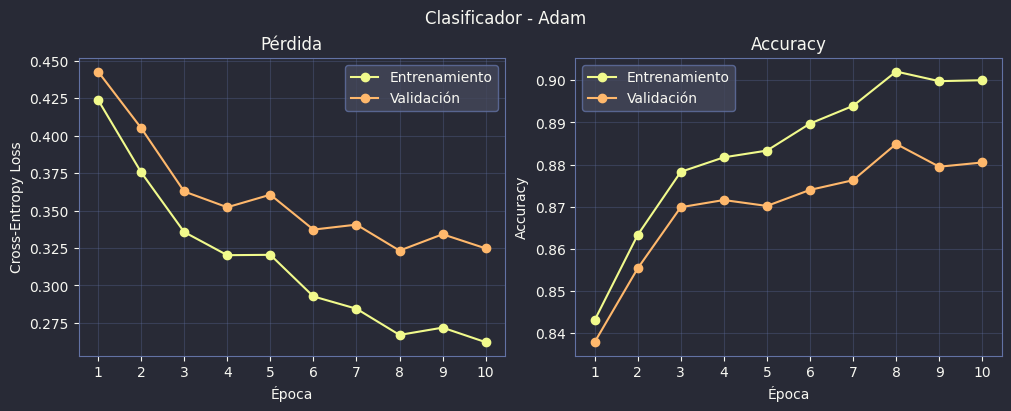

In [ ]:
view_results(10, history, "Adam")

## Ejercicio 13) Comparar *SGD* y *Adam* utilizando *validation*

Hasta este punto no necesitamos utilizar *test*.

En los Ejercicios 10, 11 y 12 entrenamos el modelo paso a paso. Para comparar configuraciones conviene **encapsular todo el experimento en una función**:

```text
fijar semillas → crear modelo → crear optimizador → entrenar → registrar métricas
```

Esto tiene dos ventajas:

- cada corrida devuelve su propio `history`, de modo que los resultados de una configuración **no sobrescriben** los de otra;
- como las semillas se fijan **dentro** de la función, cada corrida es **reproducible**: la inicialización de los pesos, el orden de los *mini-batches* y las máscaras de *Dropout* quedan determinados por `seed`, independientemente de qué celdas se hayan ejecutado antes.

Mantener constantes:
- arquitectura;
- dropout;
- batch size;
- número de épocas.

Comparar principalmente:

- `valid_loss` y `valid_acc` **de la última época**;
- velocidad de convergencia;
- estabilidad de las curvas.

**Elegir la configuración utilizando sólo *validation*.**

### 13.1) Función para ejecutar un experimento completo

`make_optimizer()` crea el optimizador a partir de su nombre y `run_experiment()` ejecuta un entrenamiento completo, igual al de los Ejercicios 10 y 11, y devuelve el modelo entrenado y su `history`.

Para evaluar *train* usamos un `DataLoader` **sin** `shuffle`: el orden no afecta a la evaluación y así no consumimos números aleatorios del generador que determina el orden de los *mini-batches* de entrenamiento.

In [ ]:
def make_optimizer(optimizer_name, model, lr):

    if optimizer_name == "SGD":
        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=lr
        )

    elif optimizer_name == "Adam":
        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=lr
        )

    else:
        raise ValueError(f"Optimizador desconocido: {optimizer_name}")

    return optimizer


def run_experiment(seed, optimizer_name, epochs, p_dropout, lr):
    torch.manual_seed(seed)

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "validation_loss": [],
        "validation_accuracy": []
    }

    model = Clasificador(p_dropout).to(device)
    optimizer = make_optimizer(optimizer_name, model, lr)

    train_eval_loader = DataLoader(
        train_set,
        batch_size=BATCH_SIZE,
        shuffle=False #Sin shuffle como lo pide la consigna
    )

    print(f"\nCOMIENZO DEL ENTRENAMIENTO OPTIMIZADOR: {optimizer_name}")
    print("________ ___ _____________ ___________ ")

    for epoch in range(1, epochs + 1):
        train_one_epoch(
            model,
            train_loader, #Creado más  arriba
            loss_fn,
            optimizer,
            device
        )

        train_loss, train_accuracy = evaluate(
            model,
            train_eval_loader,
            loss_fn,
            device
        )

        validation_loss, validation_accuracy = evaluate(
            model,
            validation_loader, #Creado más arriba
            loss_fn,
            device
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["validation_loss"].append(validation_loss)
        history["validation_accuracy"].append(validation_accuracy)

        print("_"*70)
        print(f"ÉPOCA N°{epoch}:")
        print(f"\t  PÉRDIDA ENTRENAMIENTO:  {round(train_loss, 4)} | PÉRDIDA VALIDACIÓN: {round(validation_loss, 4)}")
        print(f"\t ACCURACY ENTRENAMIENTO:  {round(train_accuracy, 4)} | ACCURACY VALIDACIÓN: {round(validation_accuracy, 4)}")

    print("\nFIN DEL ENTRENAMIENTO")
    print("___ ___ _____________\n")

    return model, history


### 13.2) Entrenar ambas configuraciones

Entrenamos SGD y Adam con la **misma semilla** y los mismos hiperparámetros, salvo el optimizador y su *learning rate*. Guardamos cada resultado en el diccionario `results`.

In [ ]:
SEED = 100

ADAM_LR = 0.001
SGD_LR = 0.01

results = {
    "adam_model": None,
    "sgd_model": None,
    "adam_history":{},
    "sgd_history": {}
}

results["adam_model"], results["adam_history"] = run_experiment(SEED, "Adam", 10, 0.2, ADAM_LR)
results["sgd_model"], results["sgd_history"] = run_experiment(SEED, "SGD", 10, 0.2, SGD_LR)


COMIENZO DEL ENTRENAMIENTO OPTIMIZADOR: Adam
________ ___ _____________ ___________ 
______________________________________________________________________
ÉPOCA N°1:
	  PÉRDIDA ENTRENAMIENTO:  0.4402 | PÉRDIDA VALIDACIÓN: 0.4589
	 ACCURACY ENTRENAMIENTO:  0.8367 | ACCURACY VALIDACIÓN: 0.8344
______________________________________________________________________
ÉPOCA N°2:
	  PÉRDIDA ENTRENAMIENTO:  0.3689 | PÉRDIDA VALIDACIÓN: 0.3923
	 ACCURACY ENTRENAMIENTO:  0.8682 | ACCURACY VALIDACIÓN: 0.857
______________________________________________________________________
ÉPOCA N°3:
	  PÉRDIDA ENTRENAMIENTO:  0.3342 | PÉRDIDA VALIDACIÓN: 0.3641
	 ACCURACY ENTRENAMIENTO:  0.8782 | ACCURACY VALIDACIÓN: 0.867
______________________________________________________________________
ÉPOCA N°4:
	  PÉRDIDA ENTRENAMIENTO:  0.3299 | PÉRDIDA VALIDACIÓN: 0.3669
	 ACCURACY ENTRENAMIENTO:  0.8772 | ACCURACY VALIDACIÓN: 0.8639
______________________________________________________________________
ÉPOCA N°5

### 13.3) Comparar las curvas

Graficamos ambas configuraciones juntas: línea continua para *validation* y línea discontinua para *train*.

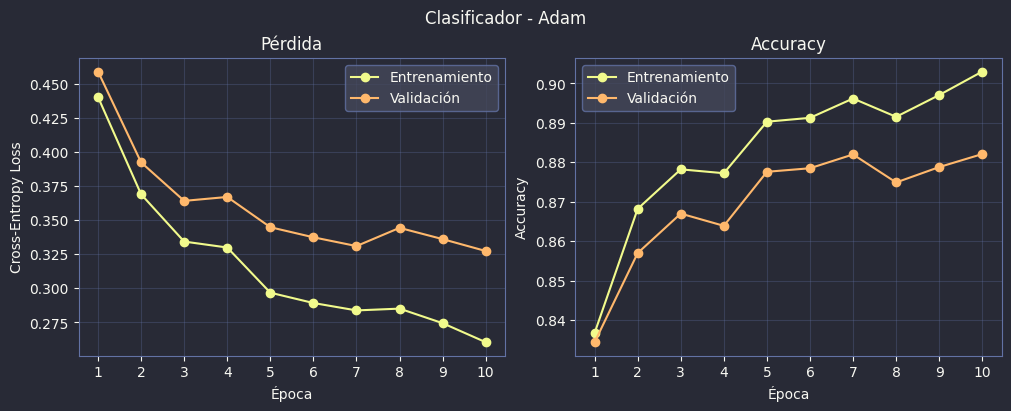

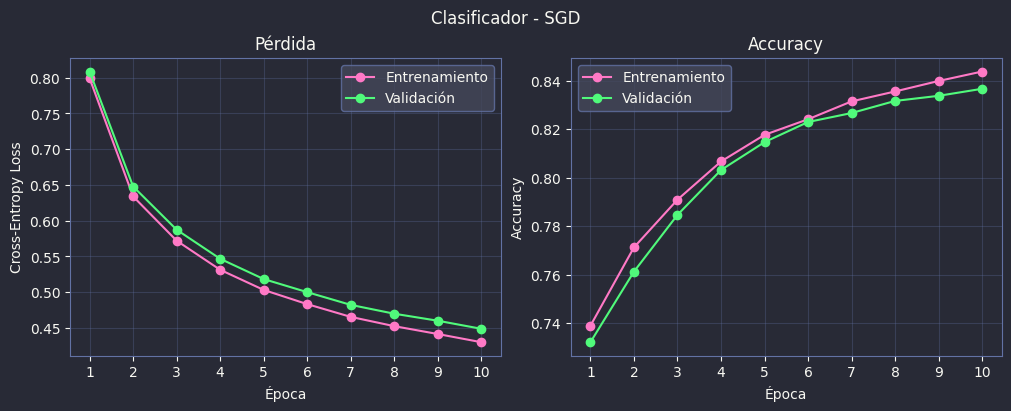

In [ ]:
view_results(10, results["adam_history"], "Adam")
view_results(10, results["sgd_history"], "SGD")

### 13.4) (Opcional) Variabilidad entre semillas

Una única corrida por configuración no permite saber si una diferencia en *validation* es **real** o es producto del azar (inicialización, orden de los *mini-batches*, *Dropout*).

Repitiendo cada configuración con varias semillas podemos estimar la media y el desvío estándar de las métricas, y preguntarnos: **¿es la diferencia entre SGD y Adam mayor que la variabilidad entre corridas?**

> Esta celda entrena $2\times3=6$ modelos, por lo que puede demorar varios minutos.

In [ ]:
seeds = [7, 150, 400]

metricas = {
    "Adam": {"loss": [], "accuracy": []},
    "SGD": {"loss": [], "accuracy": []}
}

for optimizer_name in ("Adam", "SGD"):
    for seed in seeds:
        if optimizer_name == "Adam":
            model, history = run_experiment(
                seed=seed,
                optimizer_name=optimizer_name,
                epochs=10,
                p_dropout=0.2,
                lr=ADAM_LR
            )
        else:
            model, history = run_experiment(
                seed=seed,
                optimizer_name=optimizer_name,
                epochs=10,
                p_dropout=0.2,
                lr=SGD_LR
            )

        metricas[optimizer_name]["loss"].append(
            history["validation_loss"][-1]
        )
        metricas[optimizer_name]["accuracy"].append(
            history["validation_accuracy"][-1]
        )

for optimizer_name in ("Adam", "SGD"):
    losses = metricas[optimizer_name]["loss"]
    accuracies = metricas[optimizer_name]["accuracy"]

    print(optimizer_name)
    print(f"Validation loss: {np.mean(losses):.4f} ± {np.std(losses, ddof=1):.4f}")
    print(f"Validation accuracy: {np.mean(accuracies):.4f} ± {np.std(accuracies, ddof=1):.4f}")


COMIENZO DEL ENTRENAMIENTO OPTIMIZADOR: Adam
________ ___ _____________ ___________ 
______________________________________________________________________
ÉPOCA N°1:
	  PÉRDIDA ENTRENAMIENTO:  0.4305 | PÉRDIDA VALIDACIÓN: 0.4434
	 ACCURACY ENTRENAMIENTO:  0.8386 | ACCURACY VALIDACIÓN: 0.8384
______________________________________________________________________
ÉPOCA N°2:
	  PÉRDIDA ENTRENAMIENTO:  0.3621 | PÉRDIDA VALIDACIÓN: 0.3871
	 ACCURACY ENTRENAMIENTO:  0.8672 | ACCURACY VALIDACIÓN: 0.8611
______________________________________________________________________
ÉPOCA N°3:
	  PÉRDIDA ENTRENAMIENTO:  0.3463 | PÉRDIDA VALIDACIÓN: 0.3811
	 ACCURACY ENTRENAMIENTO:  0.873 | ACCURACY VALIDACIÓN: 0.8629
______________________________________________________________________
ÉPOCA N°4:
	  PÉRDIDA ENTRENAMIENTO:  0.3232 | PÉRDIDA VALIDACIÓN: 0.3614
	 ACCURACY ENTRENAMIENTO:  0.8785 | ACCURACY VALIDACIÓN: 0.8701
______________________________________________________________________
ÉPOCA N°

### 13.5) Fijar la configuración seleccionada

Elegir el optimizador **a partir de los resultados sobre *validation*** y recuperar el modelo entrenado y su `history` correspondientes.

A partir de aquí, `model` es el **modelo final**: el que se evaluará sobre *test* en los ejercicios siguientes. Sus curvas de entrenamiento son las que corresponde mostrar en el informe.

In [ ]:
model, history = results["adam_model"], results["adam_history"]

## Ejercicio 14) Evaluar la configuración seleccionada sobre *test*

La metodología es la misma que en el *autoencoder*:

$$
\text{train}
\longrightarrow
\text{aprendizaje de parámetros},
$$

$$
\text{validation}
\longrightarrow
\text{comparación de configuraciones},
$$

$$
\text{test}
\longrightarrow
\text{evaluación final}.
$$

Recién ahora medimos el modelo sobre las 10.000 imágenes oficiales de *test*.

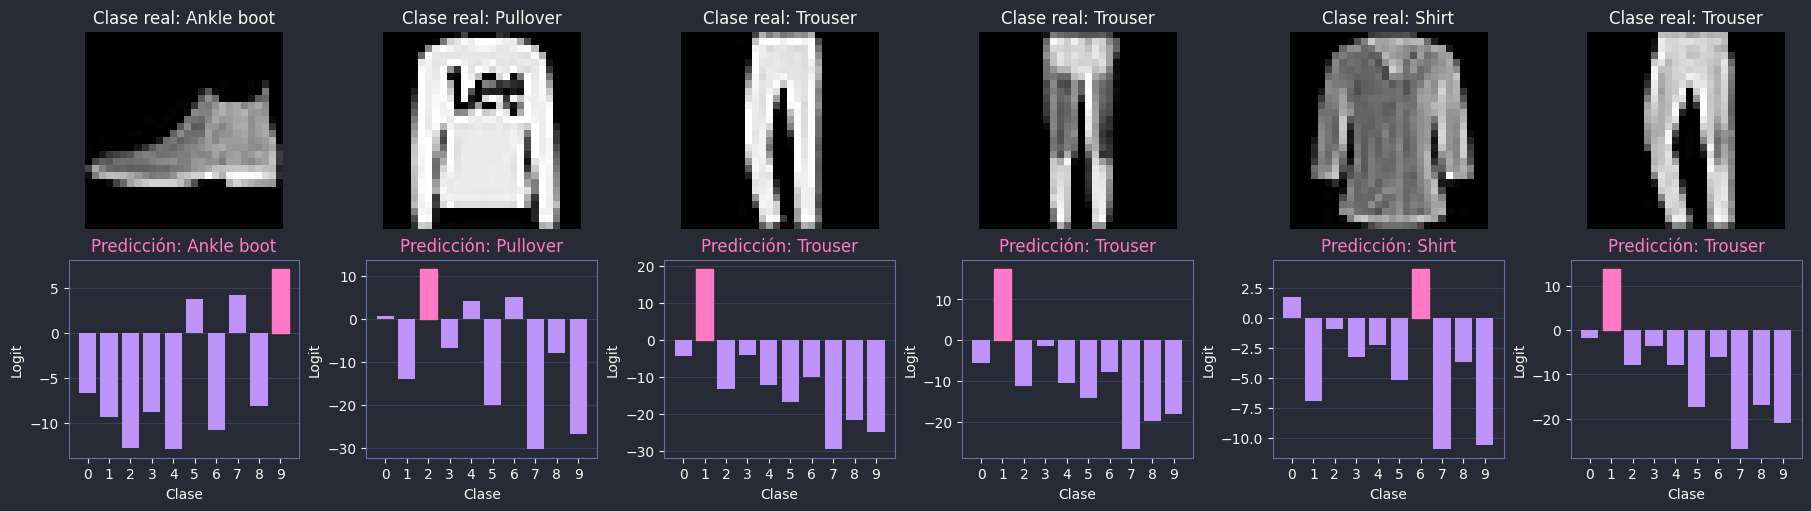

In [ ]:
show_untrained_classifications(model, test_loader, device, 6)

In [ ]:
#Evaluamos con test
test_loss, test_accuracy = evaluate(
    model,
    test_loader,
    loss_fn,
    device
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Test loss: 0.3563
Test accuracy: 87.56%


## Ejercicio 15) Visualizar errores de clasificación sobre *test*

Ahora sí podemos observar imágenes concretas del conjunto de *test* porque la configuración ya fue seleccionada.

Las imágenes **bien** clasificadas aportan poca información. Mostraremos en cambio imágenes **mal clasificadas**: observarlas ayuda a entender qué tipo de errores comete la red y si resultan razonables desde el punto de vista visual.

Como las imágenes están normalizadas a `[-1,1]`, para visualizarlas recuperamos el intervalo `[0,1]` invirtiendo la transformación: $x = 0.5\,x_{\mathrm{norm}} + 0.5$.

In [ ]:
@torch.no_grad()
def show_miss_classifications(model, data_loader, device, n=6):
    model.eval()

    fondo = "#282A36"
    texto = "#F8F8F2"
    grilla = "#6272A4"
    violeta = "#BD93F9"
    rosa = "#FF79C6"

    errores = []

    for batch_images, batch_labels in data_loader:
        batch_logits = model(batch_images.to(device)).cpu()
        batch_predictions = batch_logits.argmax(dim=1)

        for i in range(len(batch_images)):
            if batch_predictions[i].item() != batch_labels[i].item():
                errores.append((batch_images[i].cpu(), batch_labels[i].cpu(), batch_logits[i]))

                if len(errores) == n:
                    break

        if len(errores) == n:
            break

    if not errores:
        print("No se encontraron errores de clasificación.")
        return

    images = torch.stack([error[0] for error in errores])
    labels = torch.stack([error[1] for error in errores])
    logits = torch.stack([error[2] for error in errores])
    predictions = logits.argmax(dim=1)
    n = len(errores)

    fig, axes = plt.subplots(2, n,figsize=(3 * n, 5),facecolor=fondo,layout="constrained",squeeze=False)

    for i in range(n):
        real = labels[i].item()
        pred = predictions[i].item()

        ax_image = axes[0, i]
        ax_image.set_facecolor(fondo)
        imagen_normalizada = images[i, 0] * 0.5 + 0.5
        ax_image.imshow(imagen_normalizada,cmap="gray",vmin=0,vmax=1)
        ax_image.set_title(f"Clase real: {class_names[real]}",color=texto)
        ax_image.axis("off")

        ax_bar = axes[1, i]
        ax_bar.set_facecolor(fondo)

        bars = ax_bar.bar(range(10), logits[i].numpy(),color=violeta, zorder=3)
        bars[pred].set_color(rosa)

        ax_bar.set_title(f"Predicción: {class_names[pred]}",color=rosa)
        ax_bar.set_xticks(range(10))
        ax_bar.set_xlabel("Clase", color=texto)
        ax_bar.set_ylabel("Logit", color=texto)
        ax_bar.tick_params(colors=texto)
        ax_bar.grid(axis="y", color=grilla, alpha=0.3)
        ax_bar.set_axisbelow(True)

        for borde in ax_bar.spines.values():
            borde.set_color(grilla)

    plt.show()

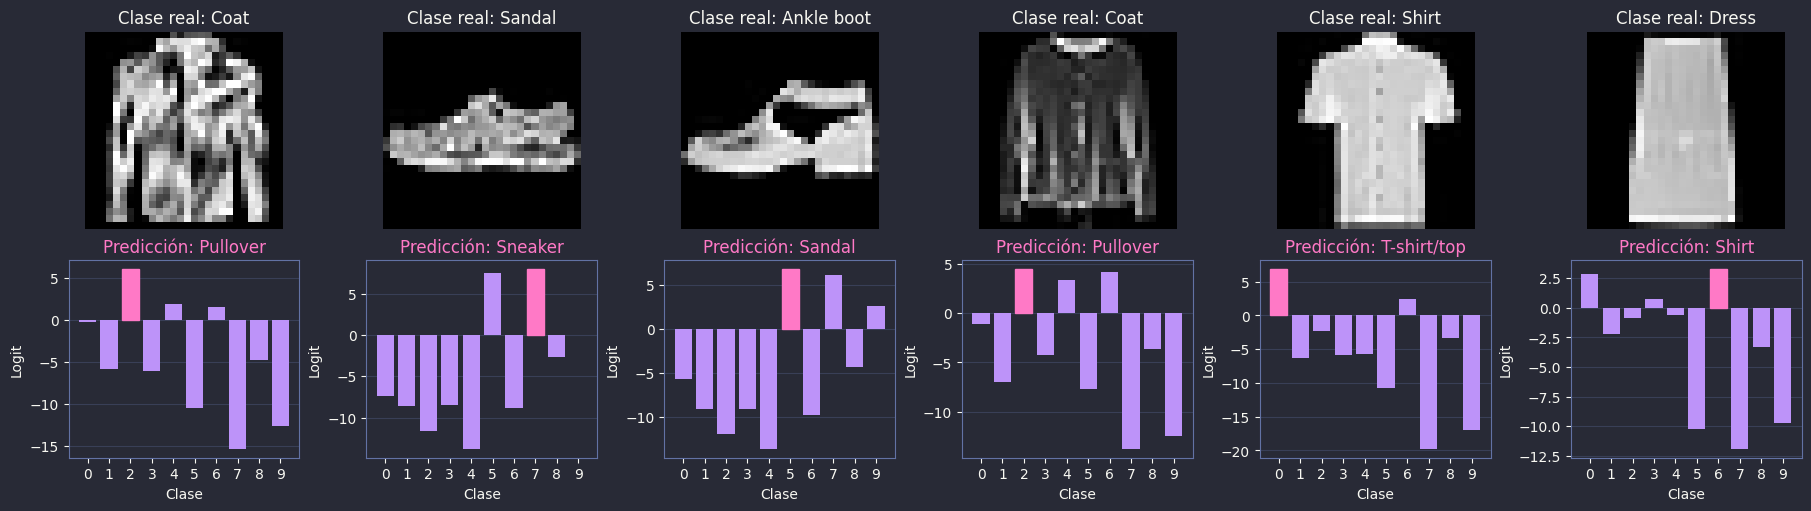

In [ ]:
show_miss_classifications(model, test_loader, device, 6)

## Ejercicio 16) *Accuracy* por clase

La *accuracy* global puede ocultar diferencias entre categorías.

Para cada clase $k$ calculamos:

$$
\mathrm{accuracy}_k
=
\frac{\mathrm{correctos\ de\ la\ clase}\ k}
{\mathrm{ejemplos\ de\ la\ clase}\ k}.
$$

Esta evaluación se hace sobre el conjunto *test* **después de haber seleccionado el modelo**.

In [ ]:
@torch.no_grad()
def show_accuracy_per_class(model, data_loader, device):
    # Guardar los resultados
    correct_classes_k = [0 for i in range(0,10)]
    total_object_examples = [0 for i in range(0,10)]
    accuracies = [0 for i in range(0,10)]

    # Recorro los batches
    model.eval()

    for batch_images, batch_labels in data_loader:
        batch_logits = model(batch_images.to(device)).cpu()
        batch_predictions = batch_logits.argmax(dim=1)

        for i in range(len(batch_images)):
            real_class = batch_labels[i].item()
            total_object_examples[real_class] += 1

            if batch_predictions[i].item() == real_class:
                correct_classes_k[real_class] += 1

    print("Preciciones x Clase (ACIERTOS)")
    print("---------- - ------")
    for i in range(0, 10):
        accuracies[i] = (correct_classes_k[i] * 100) / total_object_examples[i]
        print(f"Clase {i} - {class_names[i]}: {round(accuracies[i], 2)} %")


show_accuracy_per_class(model, test_loader, device)

Preciciones x Clase (ACIERTOS)
---------- - ------
Clase 0 - T-shirt/top: 85.5 %
Clase 1 - Trouser: 97.6 %
Clase 2 - Pullover: 80.0 %
Clase 3 - Dress: 87.8 %
Clase 4 - Coat: 80.8 %
Clase 5 - Sandal: 95.0 %
Clase 6 - Shirt: 64.4 %
Clase 7 - Sneaker: 95.0 %
Clase 8 - Bag: 96.8 %
Clase 9 - Ankle boot: 92.7 %


### 16.1) Matriz de confusión normalizada

La *accuracy* por clase resume cuántos ejemplos de cada clase fueron clasificados correctamente, pero no muestra **con qué otras clases se confunden los errores**.

Para obtener esa información utilizaremos una **matriz de confusión normalizada**.

Definimos una matriz $C$ de tamaño $10\times10$ donde:

- cada **fila** corresponde a la **clase verdadera**;
- cada **columna** corresponde a la **clase predicha**;
- $C_{ij}$ cuenta cuántos ejemplos cuya clase verdadera es $i$ fueron clasificados como clase $j$.

Por ejemplo:

$$
C_{6,0}
$$

indica cuántas imágenes cuya clase verdadera es `Shirt` fueron clasificadas como `T-shirt/top`.

La diagonal

$$
C_{00},C_{11},\ldots,C_{99}
$$

contiene las clasificaciones correctas.

Para facilitar la comparación entre clases, normalizaremos cada fila:

$$
C^{(\mathrm{norm})}_{ij}
=
\frac{C_{ij}}
{\sum_{k=0}^{9}C_{ik}}.
$$

Entonces cada fila suma aproximadamente 1:

$$
\sum_{j=0}^{9} C^{(\mathrm{norm})}_{ij}=1.
$$

De esta forma, cada elemento puede interpretarse como una **proporción de ejemplos de la clase verdadera $i$ que fueron asignados a la clase $j$**.

En una matriz de confusión normalizada ideal:

- la diagonal tendría valores cercanos a 1;
- los valores fuera de la diagonal serían cercanos a 0.

> **Importante:** esta matriz se calcula sobre `test_loader` porque ya hemos seleccionado la configuración final del modelo usando *validation*.

In [ ]:
@torch.no_grad
def confusion_matrix_norm_calculate(model, device, data_loader):
    confusion_matrix = np.zeros((10, 10)) # Cada fila representa una clase
                                        # Cada columna representa la predicción a la clase

    total_per_row = np.zeros((1,10))

    model.eval()

    for batch_images, batch_labels in test_loader:
        batch_logits = model(batch_images.to(device)).cpu()
        batch_predictions = batch_logits.argmax(dim=1)

        for i in range(len(batch_images)):
            real_class = batch_labels[i]
            predicted_class = batch_predictions[i]
            confusion_matrix[real_class, predicted_class] += 1


    #Normalizamos cada fila
    total_per_row = confusion_matrix.sum(axis=1, keepdims=True)
    confusion_matrix_norm = confusion_matrix / total_per_row

    return confusion_matrix_norm

In [ ]:
#Verificamos la normalización
print("Chequear la normalización por fila")
print("-------- -- ------------- --- ----")

confusion_matrix_norm = confusion_matrix_norm_calculate(model, device, test_loader)

for i in range(0,10):
    row_sum = confusion_matrix_norm[i].sum()
    print(f"Fila {i+1}: {round(row_sum, 2)}")


Chequear la normalización por fila
-------- -- ------------- --- ----
Fila 1: 1.0
Fila 2: 1.0
Fila 3: 1.0
Fila 4: 1.0
Fila 5: 1.0
Fila 6: 1.0
Fila 7: 1.0
Fila 8: 1.0
Fila 9: 1.0
Fila 10: 1.0


#### Visualización de la matriz

Representaremos la matriz normalizada como una imagen en escala de colores.

Para interpretar el gráfico:

- el eje vertical indica la **clase verdadera**;
- el eje horizontal indica la **clase predicha**;
- los valores de la diagonal representan **clasificaciones correctas**;
- los valores fuera de la diagonal muestran los pares de clases que la red confunde.

Como la matriz está normalizada por filas, los valores se encuentran entre 0 y 1.

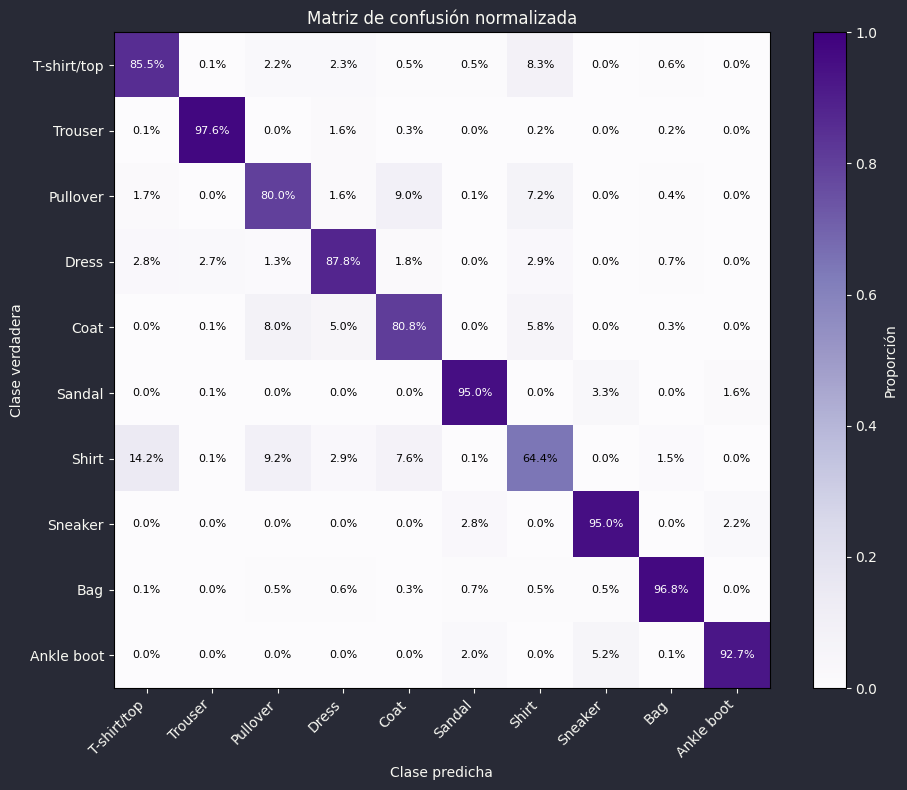

In [ ]:
fondo = "#282A36"
texto = "#F8F8F2"
grilla = "#6272A4"
violeta = "#BD93F9"
rosa = "#FF79C6"

fig, ax = plt.subplots(figsize=(10, 8), facecolor=fondo)
ax.set_facecolor(fondo)

img = ax.imshow(confusion_matrix_norm,cmap="Purples",vmin=0, vmax=1)
names = [class_names[i] for i in range(10)]

ax.set_xticks(range(10), labels=names, rotation=45, ha="right")
ax.set_yticks(range(10), labels=names)

ax.set_xlabel("Clase predicha", color=texto)
ax.set_ylabel("Clase verdadera", color=texto)
ax.set_title("Matriz de confusión normalizada", color=texto)
ax.tick_params(colors=texto)

bar = fig.colorbar(img, ax=ax)
bar.set_label("Proporción", color=texto)
bar.ax.tick_params(colors=texto)

for row in range(10):
    for col in range(10):
        val = confusion_matrix_norm[row, col] * 100
        ax.text(col, row, f"{val:.1f}%", ha="center", va="center", color="white" if val > 70 else "black",fontsize=8)


plt.tight_layout()
plt.show()

#### Cómo interpretar el resultado

La diagonal de la matriz permite observar, clase por clase, qué proporción fue clasificada correctamente.

Por ejemplo, si para una determinada clase aparece:

$$
C^{(\mathrm{norm})}_{ii}=0.91,
$$

significa que aproximadamente el 91 % de los ejemplos de esa clase fueron clasificados correctamente.

Un valor fuera de la diagonal, por ejemplo:

$$
C^{(\mathrm{norm})}_{ij}=0.08,
$$

significa que aproximadamente el 8 % de los ejemplos cuya clase verdadera es $i$ fueron confundidos con la clase $j$.

La matriz de confusión complementa la *accuracy* global porque permite responder preguntas como:

- ¿qué clases son fáciles de reconocer?
- ¿qué clases son más difíciles?
- ¿qué pares de clases se confunden frecuentemente?
- ¿los errores tienen una estructura visual razonable?

En Fashion-MNIST es especialmente interesante observar posibles confusiones entre categorías visualmente semejantes, por ejemplo prendas de la parte superior del cuerpo.

## Ejercicio 17) Preguntas conceptuales

1. ¿Por qué en clasificación necesitamos las etiquetas y en el *autoencoder* no?


> **Porque el problema que queremos resolver es que nuestro modelo pueda identificar correctamente una prenda de ropa.**


2. ¿Qué representa cada uno de los 10 *logits*?

> Cada logit representa a una puntuación de cada clase para una imágen que pasó por el modelo.


3. ¿Por qué los *logits* no son probabilidades?

> Porque luego utilizando softmax los pasamos a probabilidades, son conceptos distintos.


4. ¿Qué hace conceptualmente *softmax*?

> Softmax transforma el vector de logits en probabilidades para las distintas clases. Cada probabilidad depende del puntaje de esa clase respecto de los demás

5. ¿Por qué no agregamos `Softmax` al modelo cuando usamos `CrossEntropyLoss`?

> Por la forma de implementar CrossEntropyLoss de PyTorch ya utiliza Softmax.

6. ¿Qué recibe `CrossEntropyLoss` como predicción y como *target*?

> Como predicción recibe los logits del modelo y como target recibe las labels de cada imágen predicha, es decir la clase real.

7. ¿Qué hace `optimizer.zero_grad()`?

> Limpia los gradientes acumulados de los parámetros que gestiona el optimizador.


8. ¿Qué hace `loss.backward()`?

> Realiza la retropropagación y calcula los gradientes de la pérdida respecto de los parámetros de la red, aplicando la regla de la cadena.

9. ¿Qué hace `optimizer.step()`?

> Actualiza los parámetros del modelo utilizando los gradientes calculados por loss.backward(), según la regla del optimizador elegido y su tasa de aprendizaje.

10. ¿Por qué el bucle `for images, labels in data_loader` recorre *mini-batches*?

> Porque el DataLoader está configurado con un `batch_size` que agrupa las imágenes y sus etiquetas en mini-batches. En cada iteración entrega uno de esos grupos, lo que permite procesar varias imágenes juntas y obtener un mejor rendimiento.

11. ¿Por qué evaluamos *train* nuevamente al terminar cada época?

> Evaluamos train al terminar cada época para medir la pérdida y la accuracy del modelo con los pesos finales de esa época y en modo evaluación. Así podemos seguir su evolución y comparar esas métricas con las de validación.

12. ¿Qué diferencia existe entre `model.train()` y `model.eval()`?

> `model.train()` configura el modelo para entrenar, activando comportamientos como **Dropout**. `model.eval()` lo configura para evaluar, desactivando **Dropout**.

13. ¿Qué ocurre con *Dropout* durante evaluación?

> Dropout se desactiva durante la evaluación, por lo que todas las activaciones pasan sin descartarse aleatoriamente.

14. ¿Qué diferencia conceptual existe entre *loss* y *accuracy*?

> La loss mide cuánto se alejan las predicciones de las respuestas reales y se utiliza para guiar el entrenamiento. La accuracy indica qué proporción de ejemplos fueron clasificados correctamente

15. ¿Por qué *validation* sirve para elegir una configuración y *test* no debería utilizarse para ello?

> Porque con test queremos evaluar el modelo con imágenes que nunca vió, mientras que con el set de validation configuramos en base a los resultados obtenidos en cada etapa.

16. ¿Por qué *SGD* y *Adam* utilizan *learning rates* iniciales diferentes?
> Porque tienen reglas distintas para actualizar los parámetros. SGD aplica un learning rate común a los gradientes, mientras que Adam ajusta la escala de actualización de cada parámetro según los gradientes anteriores. Por eso se eligen learning rates iniciales adecuados para cada optimizador.

## Ejercicio 18) Experimentos sugeridos

Modificar una sola variable por vez ayuda a interpretar el efecto de cada **hiperparámetro**.

### 18.1) Learning rate con SGD

Probar:

```python
SGD_LR = 0.001
SGD_LR = 0.01
SGD_LR = 0.05
```

### 18.2) Dropout

Probar:

```python
DROPOUT_P = 0.0
DROPOUT_P = 0.2
DROPOUT_P = 0.5
```

### 18.3) Número de épocas

Probar:

```python
EPOCHS = 5
EPOCHS = 10
EPOCHS = 20
```

### 18.4) Optimizador

Comparar *SGD* y *Adam* con sus *learning rates* base.

### 18.5) Capacidad de aprendizaje del modelo

Cambiar, por ejemplo, la primera capa oculta:

```text
64 → 64 → 10
128 → 64 → 10
256 → 64 → 10
```

**Regla metodológica:** comparar configuraciones usando *validation* y reservar *test* para la configuración final.

In [ ]:
SEED = 100

SGD_LR_EXP1 = 0.001
P_DROPOUT_EXP1 = 0.0

SGD_LR_EXP2 = 0.01
P_DROPOUT_EXP2 = 0.2

SGD_LR_EXP3 = 0.05
P_DROPOUT_EXP3 = 0.5

# Convensión DROPOUT_LR_EPOCHS
results = {
    "sgd_model__0_0001_20" : None,
    "sgd_model__02_001_20"  : None,
    "sgd_model__05_005_20" : None,
    "sgd_history__0_0001_20"  : {},
    "sgd_history__02_001_20"  : {},
    "sgd_history__05_005_20" : {}
}


results["sgd_model__0_0001_20"], results["sgd_history__0_0001_20"]   = run_experiment(SEED, "SGD", 20, P_DROPOUT_EXP1, SGD_LR_EXP1)
results["sgd_model__02_001_20"], results["sgd_history__02_001_20"]   = run_experiment(SEED, "SGD", 20, P_DROPOUT_EXP2, SGD_LR_EXP2)
results["sgd_model__05_005_20"], results["sgd_history__05_005_20"] = run_experiment(SEED, "SGD", 20, P_DROPOUT_EXP3, SGD_LR_EXP3)


COMIENZO DEL ENTRENAMIENTO OPTIMIZADOR: SGD
________ ___ _____________ ___________ 
--------------------------------------------------
ÉPOCA N°1 | Perdida.Entren:  2.152 |  Perdida.Valid: 2.1545
--------------------------------------------------
ÉPOCA N°2 | Perdida.Entren:  1.8857 |  Perdida.Valid: 1.8899
--------------------------------------------------
ÉPOCA N°3 | Perdida.Entren:  1.5518 |  Perdida.Valid: 1.5562
--------------------------------------------------
ÉPOCA N°4 | Perdida.Entren:  1.2761 |  Perdida.Valid: 1.2807
--------------------------------------------------
ÉPOCA N°5 | Perdida.Entren:  1.0918 |  Perdida.Valid: 1.0976
--------------------------------------------------
ÉPOCA N°6 | Perdida.Entren:  0.9698 |  Perdida.Valid: 0.977
--------------------------------------------------
ÉPOCA N°7 | Perdida.Entren:  0.8858 |  Perdida.Valid: 0.8949
--------------------------------------------------
ÉPOCA N°8 | Perdida.Entren:  0.8257 |  Perdida.Valid: 0.8358
---------------------

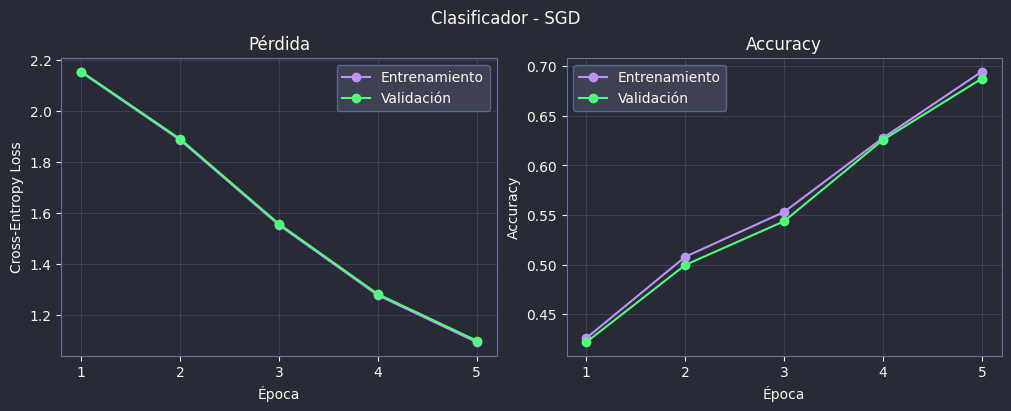

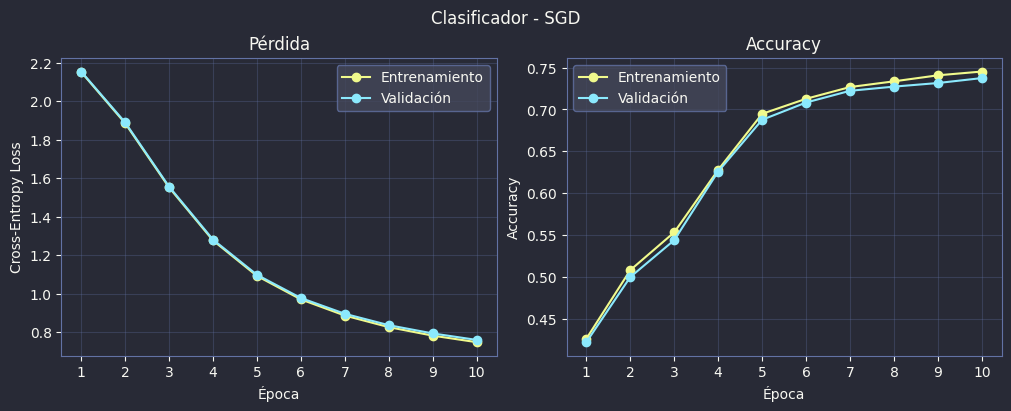

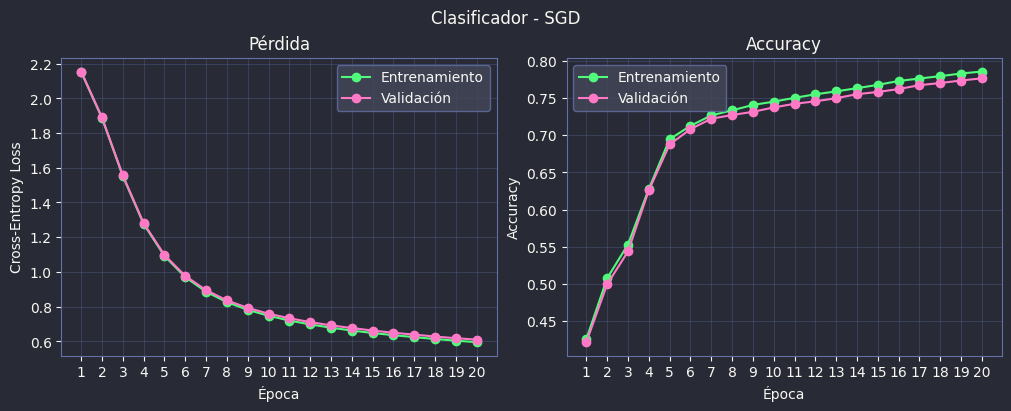

In [ ]:
view_results(5, results["sgd_history__0_0001_20"], "SGD")
view_results(10, results["sgd_history__0_0001_20"], "SGD")
view_results(20, results["sgd_history__0_0001_20"], "SGD")

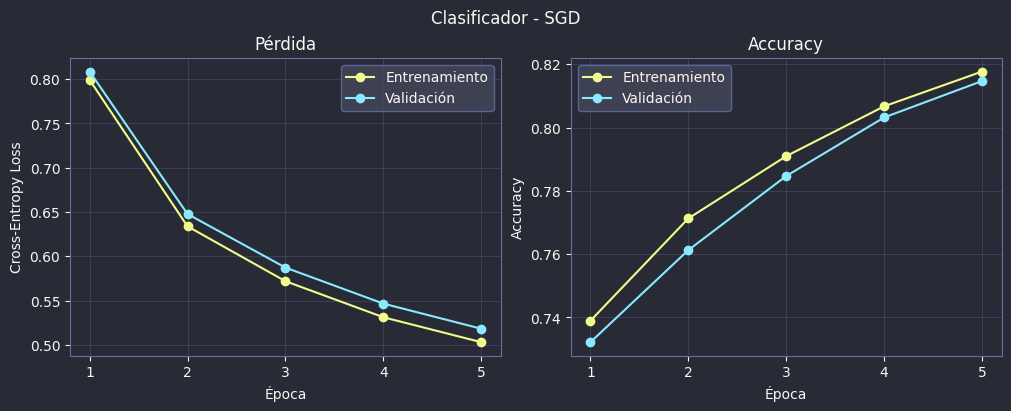

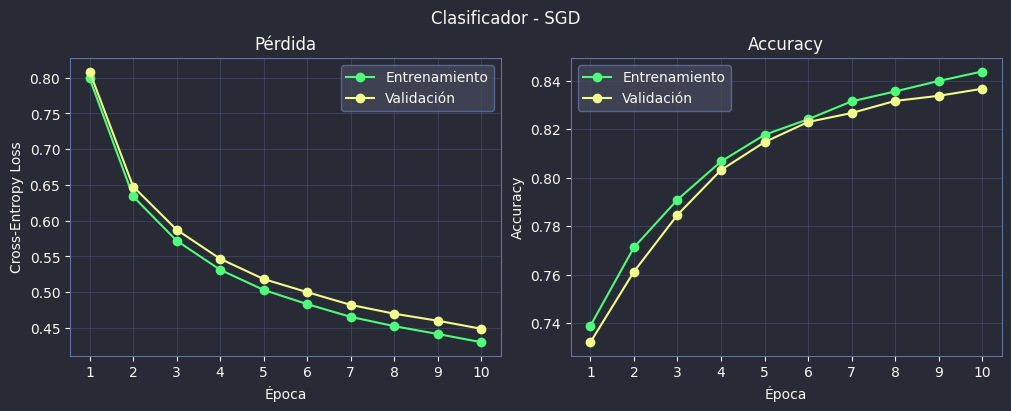

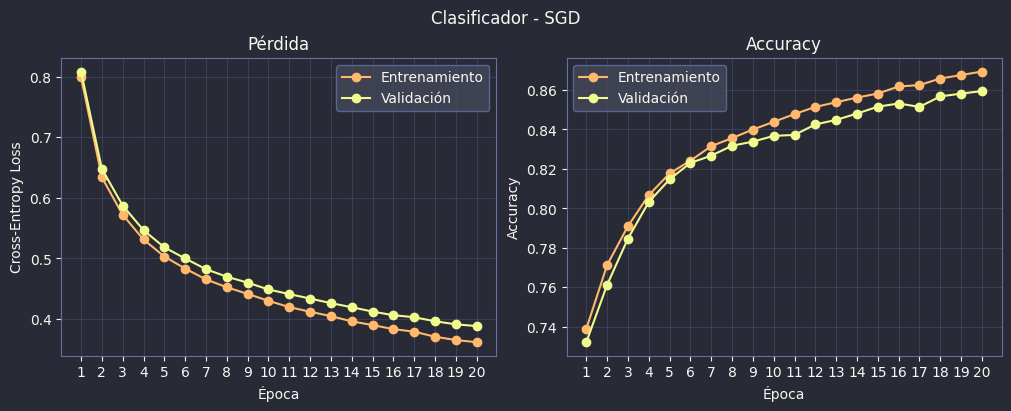

In [ ]:
view_results(5, results["sgd_history__02_001_20"], "SGD")
view_results(10, results["sgd_history__02_001_20"], "SGD")
view_results(20, results["sgd_history__02_001_20"], "SGD")

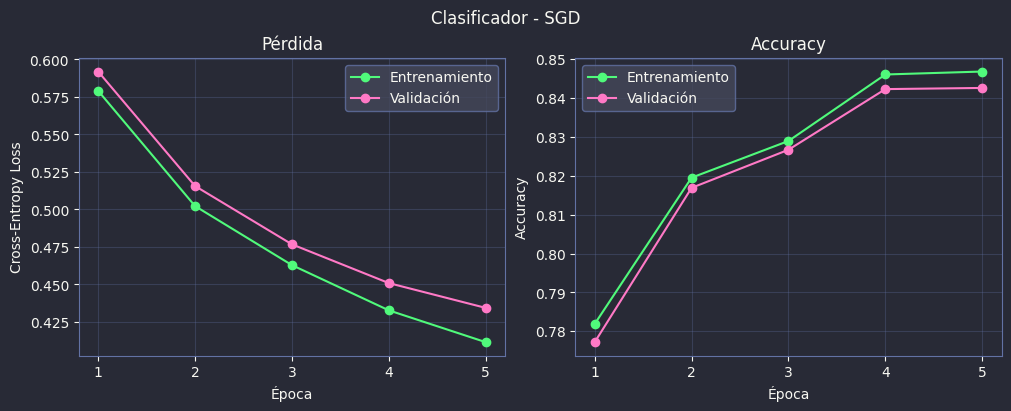

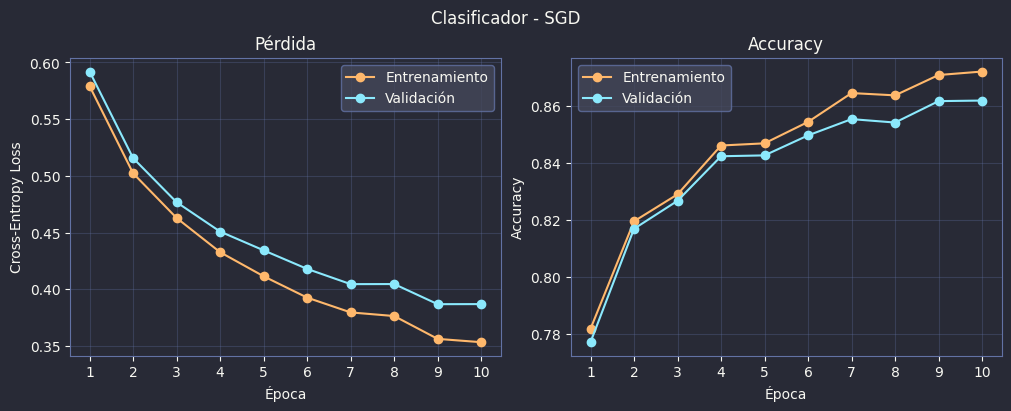

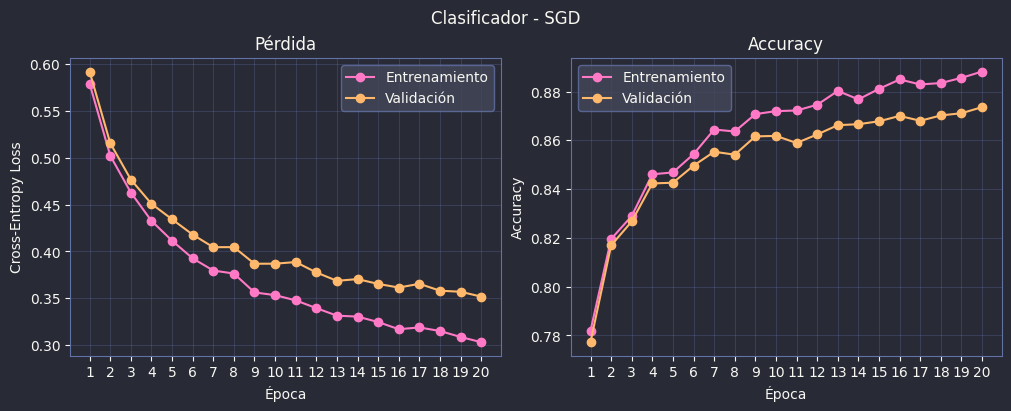

In [ ]:
view_results(5, results["sgd_history__05_005_20"], "SGD")
view_results(10, results["sgd_history__05_005_20"], "SGD")
view_results(20, results["sgd_history__05_005_20"], "SGD")

# Experimentos con SGD

In [ ]:

def view_results(epochs, histories, optimizer_name):
    paleta = ["#BD93F9", "#FF79C6", "#8BE9FD"]
    fondo = "#282A36"
    texto = "#F8F8F2"
    grilla = "#6272A4"

    fig, (ax_loss, ax_acc) = plt.subplots(
        1, 2,
        figsize=(14, 5),
        layout="constrained",
        facecolor=fondo
    )

    for (nombre, history), color in zip(histories.items(), paleta):
        n = min(epochs, len(history["train_loss"]))
        eje_epochs = range(1, n + 1)

        for ax, metrica in (
            (ax_loss, "loss"),
            (ax_acc, "accuracy")
        ):
            ax.plot(
                eje_epochs,
                history[f"train_{metrica}"][:n],
                color=color,
                 marker="o",
                linestyle="-",
                label=f"{nombre} · Train"
            )

            ax.plot(
                eje_epochs,
                history[f"validation_{metrica}"][:n],
                color=color,
                marker="o",
                linestyle="--",
                label=f"{nombre} · Validación"
            )

    ax_loss.set_title("Pérdida", color=texto)
    ax_loss.set_ylabel("Cross-Entropy Loss", color=texto)

    ax_acc.set_title("Accuracy", color=texto)
    ax_acc.set_ylabel("Accuracy", color=texto)

    for ax in (ax_loss, ax_acc):
        ax.set_facecolor(fondo)
        ax.set_xlabel("Época", color=texto)
        ax.set_xticks(range(1, epochs + 1))
        ax.tick_params(colors=texto)
        ax.grid(color=grilla, alpha=0.3)

        for borde in ax.spines.values():
            borde.set_color(grilla)

        ax.legend(
            facecolor="#44475A",
            edgecolor=grilla,
            labelcolor=texto,
            fontsize=8
        )

    fig.suptitle(
        f"Clasificador - {optimizer_name}",
        color=texto
    )

    plt.show()

In [ ]:
SEED = 100
EPOCHS = 10
P_DROPOUT = 0.2

SGD_LR_EXP1 = 0.001
SGD_LR_EXP2 = 0.01
SGD_LR_EXP3 = 0.05

results["sgd_model__02_0001_10"], results["sgd_history__02_0001_10"] = (run_experiment(SEED, "SGD", EPOCHS, P_DROPOUT, SGD_LR_EXP1))

results["sgd_model__02_001_10"], results["sgd_history__02_001_10"] = (run_experiment(SEED, "SGD", EPOCHS, P_DROPOUT, SGD_LR_EXP2))

results["sgd_model__02_005_10"], results["sgd_history__02_005_10"] = (run_experiment(SEED, "SGD", EPOCHS, P_DROPOUT, SGD_LR_EXP3))



COMIENZO DEL ENTRENAMIENTO OPTIMIZADOR: SGD
________ ___ _____________ ___________ 
______________________________________________________________________
ÉPOCA N°1:
	  PÉRDIDA ENTRENAMIENTO:  2.163 | PÉRDIDA VALIDACIÓN: 2.1656
	 ACCURACY ENTRENAMIENTO:  0.4178 | ACCURACY VALIDACIÓN: 0.4114
______________________________________________________________________
ÉPOCA N°2:
	  PÉRDIDA ENTRENAMIENTO:  1.9113 | PÉRDIDA VALIDACIÓN: 1.9154
	 ACCURACY ENTRENAMIENTO:  0.4937 | ACCURACY VALIDACIÓN: 0.4874
______________________________________________________________________
ÉPOCA N°3:
	  PÉRDIDA ENTRENAMIENTO:  1.604 | PÉRDIDA VALIDACIÓN: 1.6083
	 ACCURACY ENTRENAMIENTO:  0.5395 | ACCURACY VALIDACIÓN: 0.5295
______________________________________________________________________
ÉPOCA N°4:
	  PÉRDIDA ENTRENAMIENTO:  1.3411 | PÉRDIDA VALIDACIÓN: 1.3455
	 ACCURACY ENTRENAMIENTO:  0.6012 | ACCURACY VALIDACIÓN: 0.5996
______________________________________________________________________
ÉPOCA N°5:

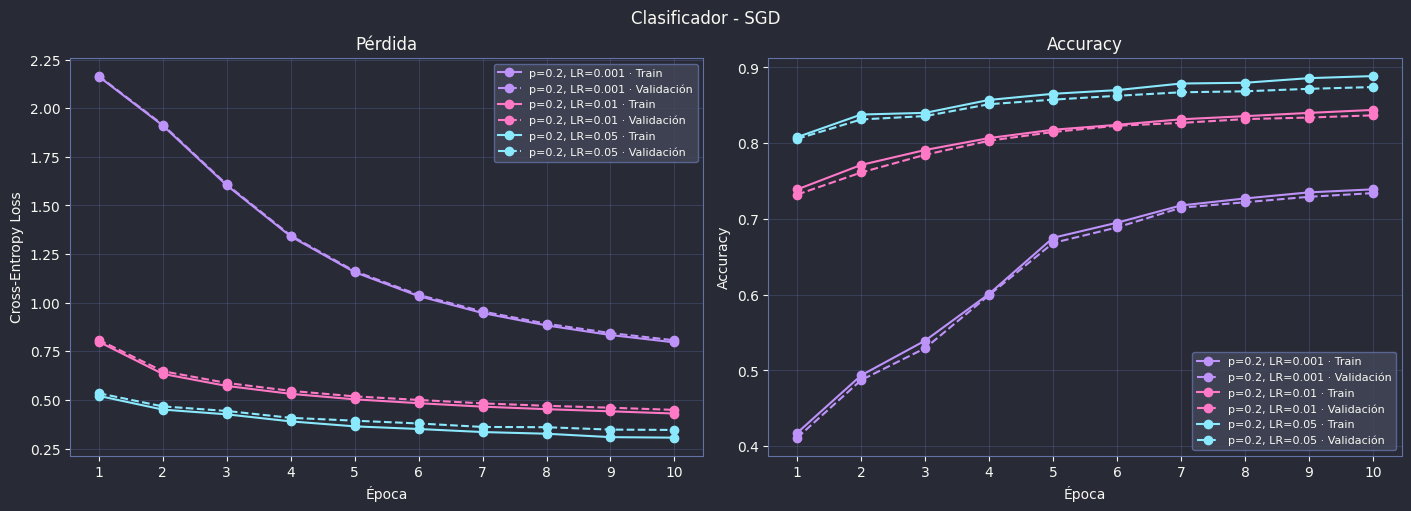

In [ ]:
histories = {
    "p=0.2, LR=0.001": results["sgd_history__02_0001_10"],
    "p=0.2, LR=0.01": results["sgd_history__02_001_10"],
    "p=0.2, LR=0.05": results["sgd_history__02_005_10"],
}

view_results(EPOCHS, histories, "SGD")

# Experimentos con Adam


In [ ]:
SEED = 100

ADAM_LR_EXP1 =  0.001
P_DROPOUT_EXP1 = 0.3

ADAM_LR_EXP2 = 0.0005
P_DROPOUT_EXP2 = 0.2

ADAM_LR_EXP3 = 0.001
P_DROPOUT_EXP3 = 0.1

# Convensión DROPOUT_LR_EPOCHS
results = {
    "adam_model__03_0001_20" : None,
    "adam_model__02_00005_20"  : None,
    "adam_model__01_0001_20" : None,
    "adam_history__03_0001_20"  : {},
    "adam_history__02_00005_20"  : {},
    "adam_history__01_0001_20" : {}
}


results["adam_model__03_0001_20"], results["adam_history__03_0001_20"]   = run_experiment(SEED, "Adam", 20, P_DROPOUT_EXP1, ADAM_LR_EXP1)
results["adam_model__02_00005_20"], results["adam_history__02_00005_20"]   = run_experiment(SEED, "Adam", 20, P_DROPOUT_EXP2, ADAM_LR_EXP2)
results["adam_model__01_0001_20"], results["adam_history__01_0001_20"] = run_experiment(SEED, "Adam", 20, P_DROPOUT_EXP3, ADAM_LR_EXP3)


COMIENZO DEL ENTRENAMIENTO OPTIMIZADOR: Adam
________ ___ _____________ ___________ 
______________________________________________________________________
ÉPOCA N°1:
	  PÉRDIDA ENTRENAMIENTO:  0.446 | PÉRDIDA VALIDACIÓN: 0.4588
	 ACCURACY ENTRENAMIENTO:  0.8343 | ACCURACY VALIDACIÓN: 0.8355
______________________________________________________________________
ÉPOCA N°2:
	  PÉRDIDA ENTRENAMIENTO:  0.393 | PÉRDIDA VALIDACIÓN: 0.4154
	 ACCURACY ENTRENAMIENTO:  0.8587 | ACCURACY VALIDACIÓN: 0.8514
______________________________________________________________________
ÉPOCA N°3:
	  PÉRDIDA ENTRENAMIENTO:  0.3554 | PÉRDIDA VALIDACIÓN: 0.3836
	 ACCURACY ENTRENAMIENTO:  0.8689 | ACCURACY VALIDACIÓN: 0.8604
______________________________________________________________________
ÉPOCA N°4:
	  PÉRDIDA ENTRENAMIENTO:  0.3492 | PÉRDIDA VALIDACIÓN: 0.3841
	 ACCURACY ENTRENAMIENTO:  0.8694 | ACCURACY VALIDACIÓN: 0.8617
______________________________________________________________________
ÉPOCA N°5

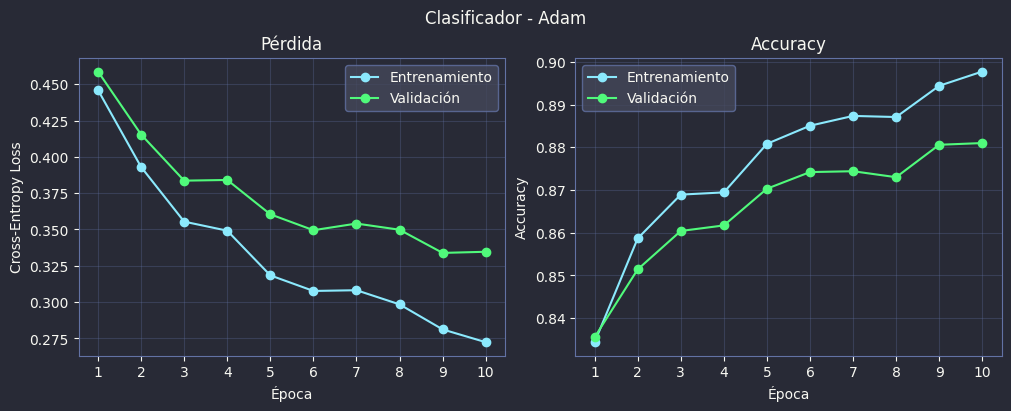

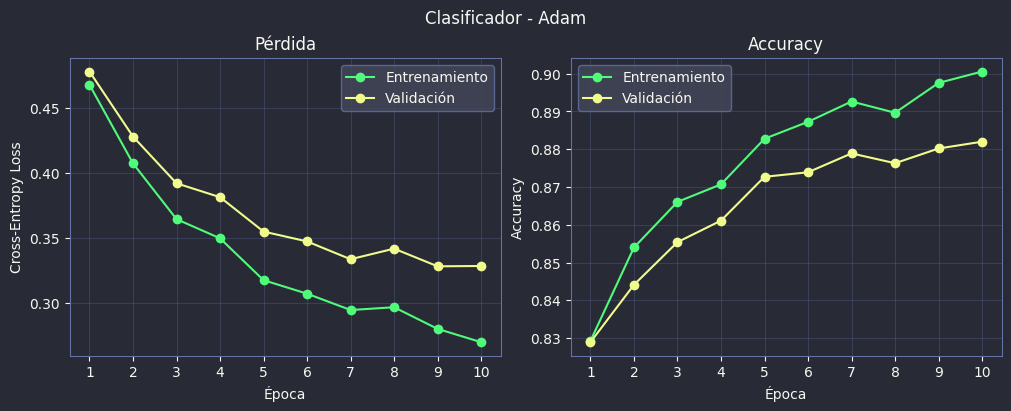

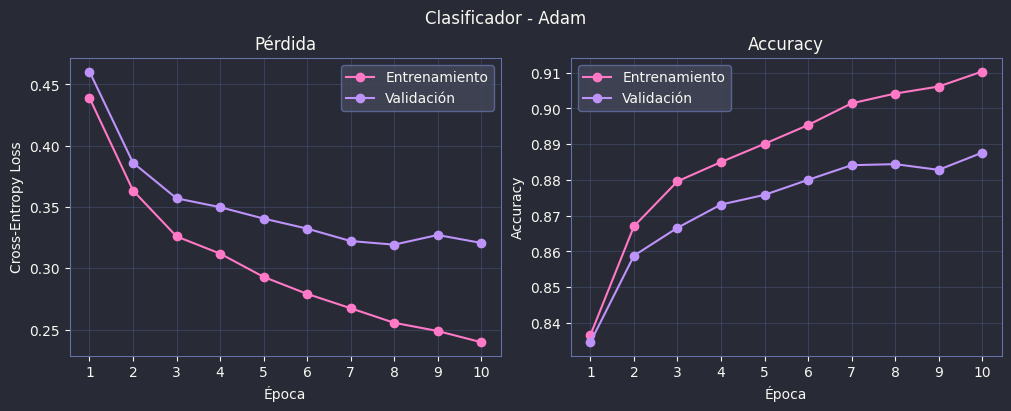

In [ ]:
model_keys = [
    "adam_history__03_0001_20",
    "adam_history__02_00005_20",
    "adam_history__01_0001_20",
]

for key in model_keys:
    model = results[key]

    view_results(10, model, "Adam")


In [ ]:
model_keys = [
    "adam_model__03_0001_20",
    "adam_model__02_00005_20",
    "adam_model__01_0001_20",
]

for key in model_keys:
    model = results[key]

    test_loss, test_accuracy = evaluate(
        model,
        test_loader,
        loss_fn,
        device
    )

    print(f"\nModelo: {key}")
    print(f"Test loss: {test_loss:.4f}")
    print(f"Test accuracy: {test_accuracy:.2%}")


Modelo: adam_model__03_0001_20
Test loss: 0.3413
Test accuracy: 87.58%

Modelo: adam_model__02_00005_20
Test loss: 0.3282
Test accuracy: 88.55%

Modelo: adam_model__01_0001_20
Test loss: 0.3411
Test accuracy: 88.47%
